In [1]:
import pandas as pd
from google.colab import files

# Upload file german.csv jika belum ada di sesi Colab
uploaded = files.upload()

# Load dataset dengan separator titik koma (;)
df = pd.read_csv('german.csv', sep=';')
print("Dataset berhasil dimuat!")
print("Dimensi Data:", df.shape)
df.head()

Saving german.csv to german.csv
Dataset berhasil dimuat!
Dimensi Data: (1000, 21)


,Creditability,Account_Balance,Duration_of_Credit_monthly,Payment_Status_of_Previous_Credit,Purpose,Credit_Amount,Value_Savings_Stocks,Length_of_current_employment,Instalment_per_cent,Sex_Marital_Status,...,Duration_in_Current_address,Most_valuable_available_asset,Age_years,Concurrent_Credits,Type_of_apartment,No_of_Credits_at_this_Bank,Occupation,No_of_dependents,Telephone,Foreign_Worker
0,1,1,18,4,2,1049,1,2,4,2,...,4,2,21,3,1,1,3,1,1,1
1,1,1,9,4,0,2799,1,3,2,3,...,2,1,36,3,1,2,3,2,1,1
2,1,2,12,2,9,841,2,4,2,2,...,4,1,23,3,1,1,2,1,1,1
3,1,1,12,4,0,2122,1,3,3,3,...,2,1,39,3,1,2,2,2,1,2
4,1,1,12,4,0,2171,1,3,4,3,...,4,2,38,1,2,2,2,1,1,2


Total Missing Value: 0

Distribusi Target (Creditability):
Creditability
1    70.0
0    30.0
Name: proportion, dtype: float64


/tmp/ipykernel_518/3586383686.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Creditability', palette='Set2')


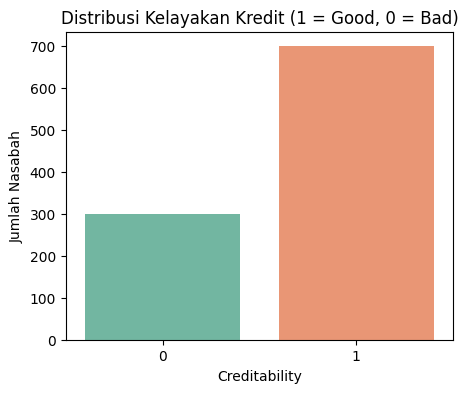

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cek missing value
print("Total Missing Value:", df.isnull().sum().sum())

# Cek persentase target
print("\nDistribusi Target (Creditability):")
print(df['Creditability'].value_counts(normalize=True) * 100)

# Visualisasi distribusi target
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='Creditability', palette='Set2')
plt.title('Distribusi Kelayakan Kredit (1 = Good, 0 = Bad)')
plt.xlabel('Creditability')
plt.ylabel('Jumlah Nasabah')
plt.show()


In [4]:
# Statistik deskriptif untuk durasi, jumlah kredit, umur, dan persentase angsuran
num_cols = ['Duration_of_Credit_monthly', 'Credit_Amount', 'Age_years', 'Instalment_per_cent']
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Duration_of_Credit_monthly,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
Credit_Amount,1000.0,3271.248,2822.751760,250.0,1365.5,2319.5,3972.25,18424.0
Age_years,1000.0,35.542,11.352670,19.0,27.0,33.0,42.00,75.0
Instalment_per_cent,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0


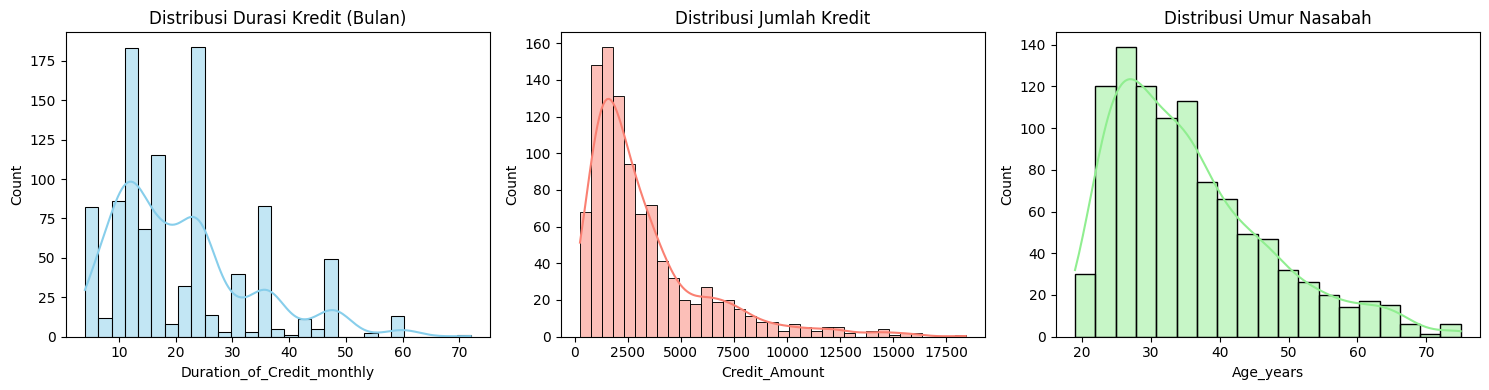

In [5]:
# Histplot fitur utama
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['Duration_of_Credit_monthly'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribusi Durasi Kredit (Bulan)')

sns.histplot(df['Credit_Amount'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribusi Jumlah Kredit')

sns.histplot(df['Age_years'], kde=True, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribusi Umur Nasabah')

plt.tight_layout()
plt.show()

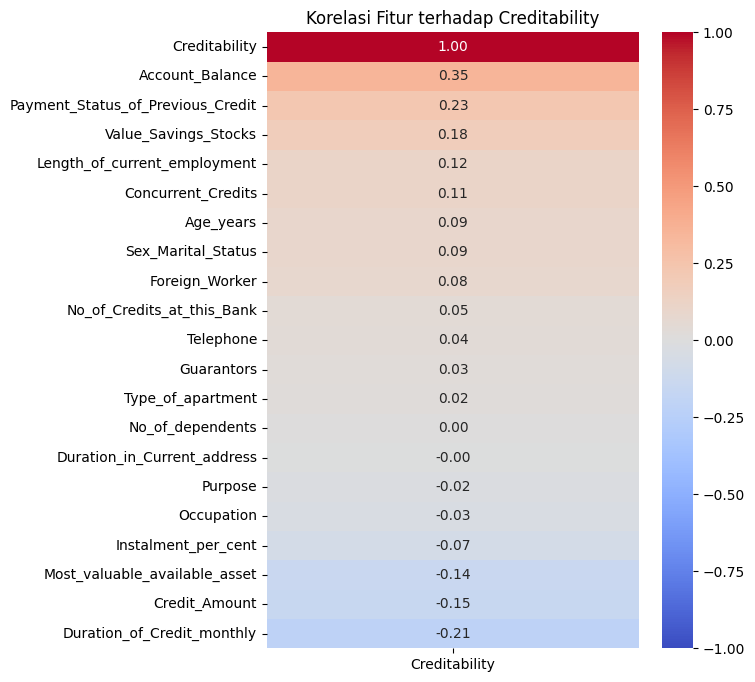

In [6]:
# Korelasi seluruh fitur terhadap target Creditability
plt.figure(figsize=(6, 8))
corr_target = df.corr()[['Creditability']].sort_values(by='Creditability', ascending=False)
sns.heatmap(corr_target, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Korelasi Fitur terhadap Creditability')
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separasi Fitur (X) dan Target (y)
X = df.drop(columns=['Creditability'])
y = df['Creditability']

# Splitting Data (80% Train, 20% Test) dengan stratify agar rasio kelas tetap seimbang
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling fitur numerik (opsional untuk Tree-based model, tapi sangat membantu stabilitas)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data Train Shape:", X_train.shape)
print("Data Test Shape :", X_test.shape)

Data Train Shape: (800, 20)
Data Test Shape : (200, 20)


In [9]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 1. Inisialisasi Model Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

# 2. Inisialisasi Model XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

# Training Model
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

print("Training selesai untuk kedua model!")

Training selesai untuk kedua model!


In [11]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Prediksi Random Forest
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Prediksi XGBoost
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("=== RANDOM FOREST CLASSIFICATION REPORT ===")
print(classification_report(y_test, rf_pred))
print("ROC-AUC Score RF:", roc_auc_score(y_test, rf_prob))

print("\n" + "="*50 + "\n")

print("=== XGBOOST CLASSIFICATION REPORT ===")
print(classification_report(y_test, xgb_pred))
print("ROC-AUC Score XGB:", roc_auc_score(y_test, xgb_prob))

=== RANDOM FOREST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.66      0.55      0.60        60
           1       0.82      0.88      0.85       140

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200

ROC-AUC Score RF: 0.821904761904762


=== XGBOOST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.69      0.55      0.61        60
           1       0.82      0.89      0.86       140

    accuracy                           0.79       200
   macro avg       0.75      0.72      0.73       200
weighted avg       0.78      0.79      0.78       200

ROC-AUC Score XGB: 0.8146428571428571


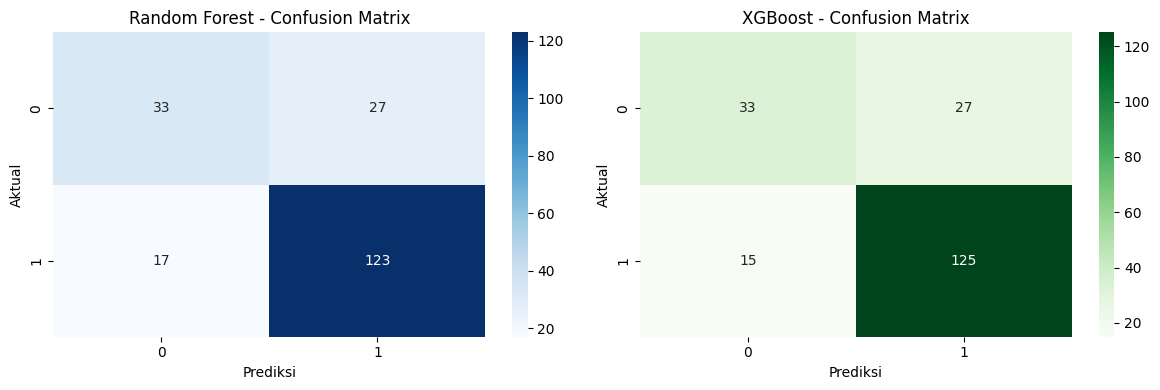

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Confusion Matrix RF
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Random Forest - Confusion Matrix')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Confusion Matrix XGBoost
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('XGBoost - Confusion Matrix')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

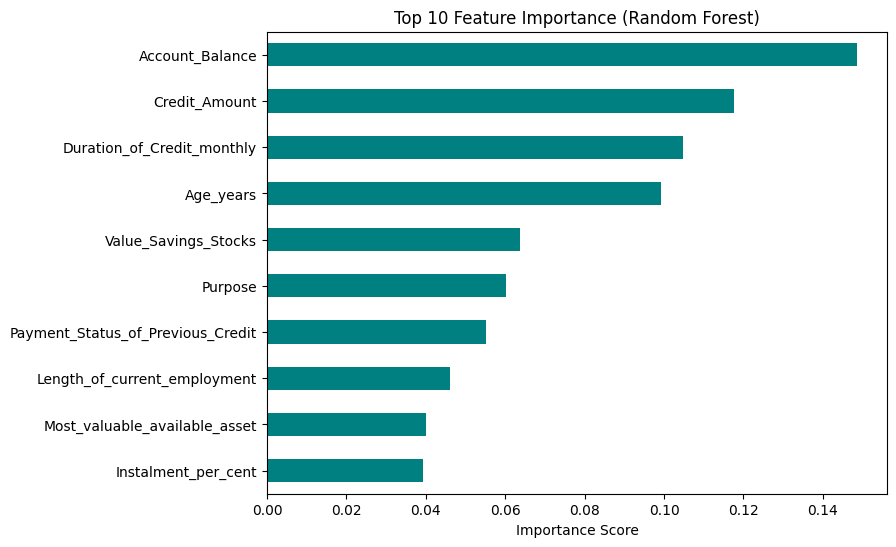

In [13]:
import pandas as pd

# Menganalisis fitur paling berpengaruh di model Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importances.tail(10).plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importance (Random Forest)')
plt.xlabel('Importance Score')
plt.show()